In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score
import sys
from pathlib import Path

# Detect project root and add it to sys.path
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

# Now this import will work without error:
from src.data_preprocessing import load_dataset, ALL_FEATURES, URL_FEATURES
from src.models_common import ShiftedCategoricalNB
from src.data_preprocessing import load_dataset, get_preprocessed_data, URL_FEATURES,ALL_FEATURES
from sklearn.preprocessing import StandardScaler

In [ ]:
df = load_dataset()

In [20]:
df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [10]:
df.shape

(11055, 31)

In [21]:
X = df[ALL_FEATURES]
y = df['Result'].map({-1:1,1:0}) #1 = Phishing, 0 = Legitimate

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [23]:
X_scaled

array([[-1.3836833 ,  2.13194274,  0.38761387, ...,  0.40215372,
         1.15102939, -2.47633965],
       [ 0.72270873,  2.13194274,  0.38761387, ...,  0.40215372,
         1.15102939,  0.40382183],
       [ 0.72270873,  0.82656323,  0.38761387, ...,  0.40215372,
        -0.60360794, -2.47633965],
       ...,
       [ 0.72270873, -0.47881627,  0.38761387, ...,  0.40215372,
        -0.60360794,  0.40382183],
       [-1.3836833 , -0.47881627,  0.38761387, ...,  0.40215372,
         1.15102939,  0.40382183],
       [-1.3836833 , -0.47881627,  0.38761387, ..., -2.48661132,
         1.15102939, -2.47633965]], shape=(11055, 30))

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca_full = PCA()
pca_full.fit(X_scaled)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

In [25]:
cumulative_variance

array([0.17859628, 0.31455653, 0.40171214, 0.45446002, 0.50235153,
       0.54176303, 0.57973113, 0.61648996, 0.65158291, 0.68294401,
       0.71373752, 0.74365977, 0.77298593, 0.80041181, 0.82703732,
       0.84955339, 0.86943866, 0.88856054, 0.90319157, 0.91706812,
       0.93038592, 0.94282363, 0.95367477, 0.96408797, 0.97350395,
       0.98151186, 0.98888079, 0.99401149, 0.99825017, 1.        ])

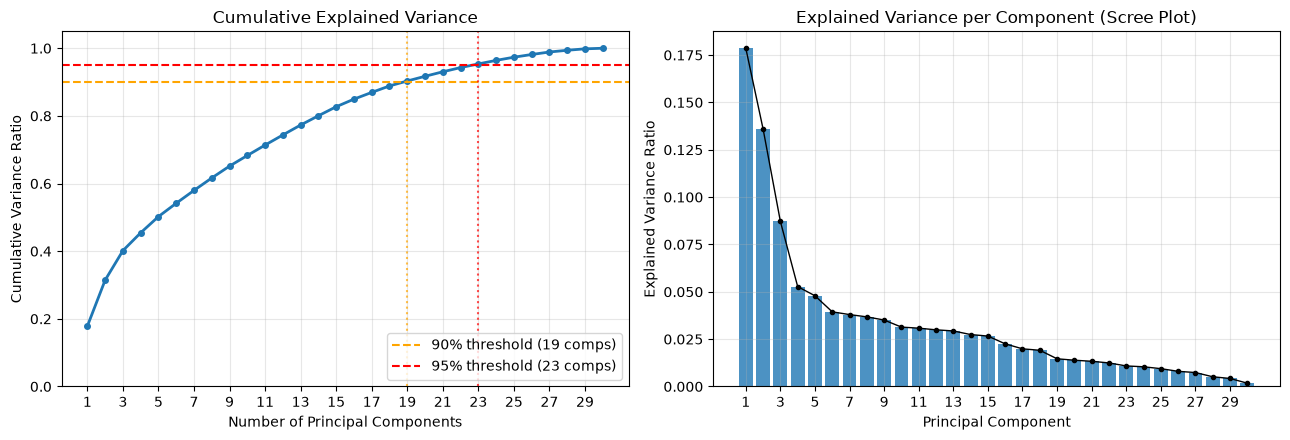

In [26]:
n_components = len(cumulative_variance)
components_x = np.arange(1, n_components + 1)
individual_variance = pca_full.explained_variance_ratio_

# Count components needed for 90% and 95% thresholds
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Cumulative Explained Variance
ax1.plot(components_x, cumulative_variance, marker="o", markersize=4, linewidth=2)
ax1.axhline(0.90, color="orange", linestyle="--", label=f"90% threshold ({n_90} comps)")
ax1.axhline(0.95, color="red", linestyle="--", label=f"95% threshold ({n_95} comps)")
ax1.axvline(n_90, color="orange", linestyle=":", alpha=0.7)
ax1.axvline(n_95, color="red", linestyle=":", alpha=0.7)
ax1.set_title("Cumulative Explained Variance")
ax1.set_xlabel("Number of Principal Components")
ax1.set_ylabel("Cumulative Variance Ratio")
ax1.set_xticks(np.arange(1, n_components + 1, 2))
ax1.set_ylim(0, 1.05)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="lower right")

# 2. Individual Explained Variance (Scree Plot)
ax2.bar(components_x, individual_variance, alpha=0.8, label="Individual")
ax2.plot(components_x, individual_variance, color="black", marker=".", linewidth=1)
ax2.set_title("Explained Variance per Component (Scree Plot)")
ax2.set_xlabel("Principal Component")
ax2.set_ylabel("Explained Variance Ratio")
ax2.set_xticks(np.arange(1, n_components + 1, 2))
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
thresholds = [0.90, 0.92, 0.94, 0.95, 0.98]
for t in thresholds:
    k = np.argmax(cumulative_variance >= t) + 1
    print(f"Variance: {int(t*100)}% -> {k} components (out of 30)")

Variance: 90% -> 19 components (out of 30)
Variance: 92% -> 21 components (out of 30)
Variance: 94% -> 22 components (out of 30)
Variance: 95% -> 23 components (out of 30)
Variance: 98% -> 26 components (out of 30)


Training Baseline Random Forest (30 raw features)...

=== Model Comparison: Baseline vs PCA Random Forest ===


,Setting,Components,Variance Captured,Test Accuracy (%),Train Time (s)
0,Baseline (All 30 Features),30,100%,97.60,0.199
1,PCA (90% Variance),19,90.3%,96.52,0.471
2,PCA (92% Variance),21,93.0%,96.43,0.478
3,PCA (94% Variance),22,94.3%,96.52,0.507
4,PCA (95% Variance),23,95.4%,96.70,0.472
5,PCA (98% Variance),26,98.2%,96.79,0.566


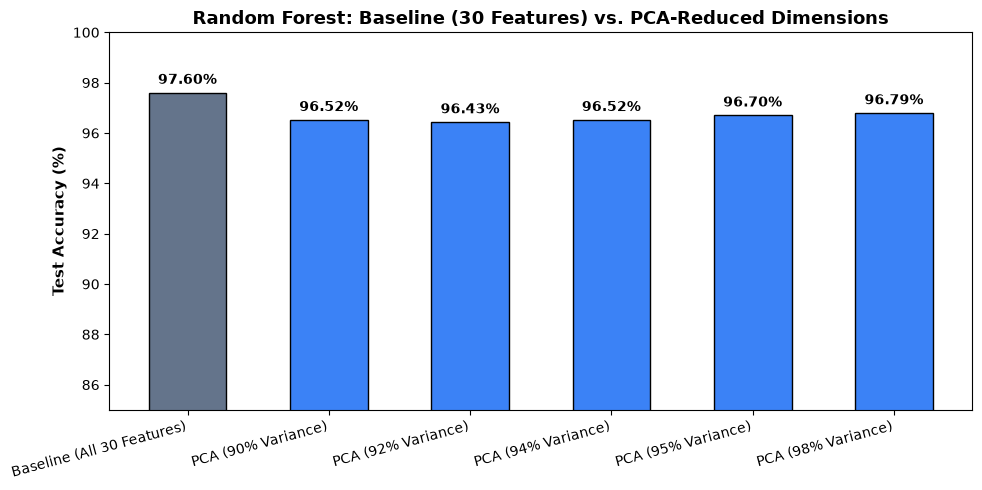

In [28]:
import time
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------
# 1. Stratified Train-Test Split (Same 80/20 as Track A)
# ----------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fit scaler only on train data to prevent leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ----------------------------------------------------
# 2. Baseline: Random Forest on all 30 Raw Features
# ----------------------------------------------------
print("Training Baseline Random Forest (30 raw features)...")
t0 = time.time()
rf_baseline = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
rf_baseline.fit(X_train, y_train)
t_base = time.time() - t0
acc_baseline = accuracy_score(y_test, rf_baseline.predict(X_test))

results = [{
    "Setting": "Baseline (All 30 Features)",
    "Components": 30,
    "Variance Captured": "100%",
    "Test Accuracy (%)": round(acc_baseline * 100, 2),
    "Train Time (s)": round(t_base, 3)
}]

# ----------------------------------------------------
# 3. Train Random Forest across PCA Thresholds (90% - 98%)
# ----------------------------------------------------
thresholds = [0.90, 0.92, 0.94, 0.95, 0.98]

for t in thresholds:
    # Fit PCA on training set for the given explained variance
    pca = PCA(n_components=t, random_state=42)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)
    
    n_comps = pca.n_components_
    actual_var = np.sum(pca.explained_variance_ratio_)
    
    # Train Random Forest on principal components
    t0 = time.time()
    rf_pca = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
    rf_pca.fit(X_train_pca, y_train)
    t_train = time.time() - t0
    
    acc_pca = accuracy_score(y_test, rf_pca.predict(X_test_pca))
    
    results.append({
        "Setting": f"PCA ({int(t*100)}% Variance)",
        "Components": n_comps,
        "Variance Captured": f"{actual_var*100:.1f}%",
        "Test Accuracy (%)": round(acc_pca * 100, 2),
        "Train Time (s)": round(t_train, 3)
    })

# ----------------------------------------------------
# 4. Display Comparison Table
# ----------------------------------------------------
results_df = pd.DataFrame(results)
print("\n=== Model Comparison: Baseline vs PCA Random Forest ===")
display(results_df)

# ----------------------------------------------------
# 5. Visual Comparison Chart
# ----------------------------------------------------
fig, ax1 = plt.subplots(figsize=(10, 5))

colors = ['#64748b'] + ['#3b82f6']*5
bars = ax1.bar(results_df["Setting"], results_df["Test Accuracy (%)"], color=colors, edgecolor="black", width=0.55)
ax1.set_ylabel("Test Accuracy (%)", fontsize=11, fontweight="bold")
ax1.set_title("Random Forest: Baseline (30 Features) vs. PCA-Reduced Dimensions", fontsize=13, fontweight="bold")
ax1.set_ylim(85, 100)
ax1.bar_label(bars, fmt="%.2f%%", padding=4, fontweight="bold")

plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()